# Week 06: Stats for Business: Is the Price Right?

You just joined the pricing team at a car-listing marketplace. Your manager has a few questions and one rule: **every claim needs a number, and every number needs a reason to trust it.**

**Data:** `cars.csv`: about 12,000 car trims (1990–2017) with specs and sticker price (MSRP). Source: [Car Features and MSRP (Kaggle)](https://www.kaggle.com/datasets/CooperUnion/cardataset). It's real data, so it's messy.

**What you'll practice** (all from this week's lecture):
- Cleaning before describing
- Mean vs median, skew, log transforms
- z-scores
- Bootstrap confidence intervals
- One- and two-sample tests, and picking the right one
- Confounding, and significant vs important

**How to answer:** Fill in the code cells, then write 1–3 sentences in each **Answer:** cell. Code without an interpretation is only half the job.

Plan for about 2–3 hours. 🚀 questions are optional stretch.

## Setup

In [3]:
# run this first if you dont have them installed in your env
!python -m pip install pandas numpy matplotlib scipy

  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ----------------------- ---------------- 5.5/9.3 MB 26.0 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 23.6 MB/s  0:00:00
Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl (36.6 MB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 18.8 MB/s  0:00:00

   ---------------------------------------- 0/7 [scipy]
   ---------------------------------------- 0/7 [scipy]
   ---------------------------------------- 0/7 [scipy]
   ---------------------------------------- 0/7 [scipy]
   ---------------------------------------- 0/7 [scipy]
   ---------------------------------------- 0/7 [scipy]
   ---------------------------------------- 0/7 [scipy]
   ---------------------------------------- 0/7 [scipy]
   ---------------------------------------- 0/7 [scipy]


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", None)
rng = np.random.default_rng(42)  # use rng for all random sampling so your results are reproducible

df = pd.read_csv("../data/cars.csv")
print(df.shape)
df.head()

(11914, 15)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,18,3916,34500


---
## Part 1: Can you trust this data?

### Q1. Find the problems before you average anything

This dataset has **at least five** real problems. Find them, fix or flag each one, and build a cleaned DataFrame called `clean`. You'll use `clean` for the rest of the notebook.

Use your Week 02 cleaning checklist. Some nudges, in no particular order:
- Count things twice.
- The most common value in a column can be more suspicious than the largest one.
- Would you print every max value in a sales brochure?
- Missing values usually have a reason. *Who* is missing?
- Is every number in a column measured in the same unit?
- Does every column vary at the level you'd expect?
- Not everything weird is wrong.

For each problem, decide: **drop it, set it to NaN, flag it, or leave it**. Dropping whole rows is the last resort, because a row with a bad price may still have a good MPG.

In [ ]:
# Explore here. Add as many cells as you need.
# Useful: .duplicated(), .value_counts(), .describe(), .isna().sum(), .nlargest(), .groupby(...).nunique()

#clean = df.copy()
#clean.value_counts()
#clean["MSRP"] = clean["MSRP"].replace(2000, np.nan)


#clean.duplicated().sum()
#clean.drop_duplicates()


#clean.describe()
#clean[clean["highway MPG"] == 354].count()
#clean.loc[clean["highway MPG"] == 354, "highway MPG"] = np.nan

#clean.isna().sum()

#clean["Transmission Type"].value_counts()
#clean.loc[clean["Transmission Type"] == "UNKNOWN", "Transmission Type"] = np.nan
#clean["Transmission Type"].value_counts()



Transmission Type
AUTOMATIC           8266
MANUAL              2935
AUTOMATED_MANUAL     626
DIRECT_DRIVE          68
Name: count, dtype: int64

**Cleaning log:** fill in one row per problem.

| # | Problem | How I found it | Rows affected | What I did | Why |
|---|---|---|---|---|---|
| 1 |Some MSRP are 2000 |clean.value_counts() |1036 |Replaced 2000 MSRP wih Nan |2000s were placeholders |
| 2 |Duplicated rows |clean.duplicated().sum() |720 |clean.drop_duplicates() |Don't need duplicater rows |
| 3 |Highway mpg of 354 |df.describe() |1 |Replaced 354 with nan |Highway mpg of 354 is not possible |
| 4 |Doors, HP, cylinders, etc. have NaNs |df.isna().sum() |102 |Kept them |Would erase too many rows |
| 5 |Transmission Type Unknowns |clean["Transmission Type"].value_counts() |19 |clean.loc[clean["Transmission Type"] == "UNKNOWN", "Transmission Type"] = np.nan |Can't be assigned to automatic or manual |

In [27]:
# Build your cleaned DataFrame. Start from a copy so df stays untouched.
clean = df.copy()
clean.columns = clean.columns.str.strip().str.lower().str.replace(" ", "_")  # freebie: snake_case names

clean.value_counts()
clean["msrp"] = clean["msrp"].replace(2000, np.nan)


clean.duplicated().sum()
clean.drop_duplicates()


clean.describe()
clean[clean["highway_mpg"] == 354].count()
clean.loc[clean["highway_mpg"] == 354, "highway MPG"] = np.nan

clean.isna().sum()

clean["transmission_type"].value_counts()
clean.loc[clean["transmission_type"] == "UNKNOWN", "transmission_type"] = np.nan
clean["transmission_type"].value_counts()


transmission_type
AUTOMATIC           8266
MANUAL              2935
AUTOMATED_MANUAL     626
DIRECT_DRIVE          68
Name: count, dtype: int64

In [28]:
# Checkpoint: run this before moving on.
print(clean.shape)
print(clean.isna().sum()[clean.isna().sum() > 0])
# Fewer than ~10,000 rows? You probably dropped too much. Go back and use NaN or a flag instead.

(11914, 16)
engine_fuel_type         3
engine_hp               69
engine_cylinders        30
transmission_type       19
number_of_doors          6
msrp                  1036
highway MPG          11914
dtype: int64


---
## Part 2: Describe

### Q2. What does a "typical" car cost?

Your manager wants one number for "typical price" on the homepage.

a) Compute the mean and median MSRP. Which is bigger, and why?

b) Plot a histogram of MSRP, then a histogram of `np.log10(msrp)`. Describe each shape in a few words.

c) What percent of cars cost more than the mean?

d) Which number belongs on the homepage? Why?

Mean: 44270.43
Median: 31602.50
24.4% cars cost more than the mean


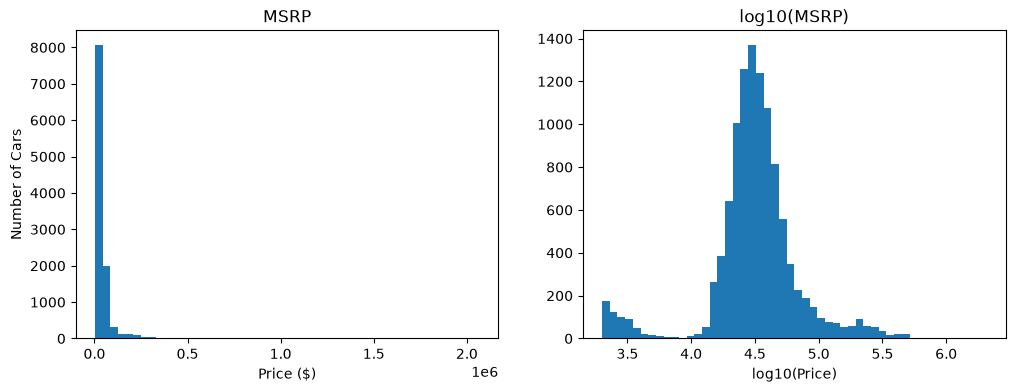

In [29]:
# a) mean and median

prices = clean["msrp"].dropna()
meanPrice = prices.mean()
medianPrice = prices.median()
print(f"Mean: {meanPrice:.2f}")
print(f"Median: {medianPrice:.2f}")

# Mean: 44270.7
# Median: 31602.50

# The mean is larger because there are more large outliers that skew the data which is reflected on the mean.
# Meanwhile the median is only the number in the middle and is not affected by outliers.

# b) two histograms side by side (plt.subplots(1, 2))

fig, axes = plt.subplots(1,2, figsize=(12,4))

axes[0].hist(prices, bins=50)
axes[0].set_title("MSRP")
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("Number of Cars")

axes[1].hist(np.log10(prices), bins=50)
axes[1].set_title("log10(MSRP)")
axes[1].set_xlabel("log10(Price)")

# c) share of cars above the mean

cars_above_mean = prices[prices > meanPrice].count()
cars_above_mean_percentage = cars_above_mean / prices.count()

print(f"{(cars_above_mean_percentage* 100):.1f}% cars cost more than the mean")
# 24.4% cars cost more than the mean


**Answer D: The median should be on the homepage since it is more representative of the typical price**

### Q3. Fuel-efficient *for its size*?

Two 2017 cars:
- **Honda Civic** (Compact): 42 highway MPG
- **Volvo S90** (Large): 34 highway MPG

The Civic wins on raw MPG, but large cars are heavier. Which one is more impressive *for its class*?

a) For 2017 cars (only the MPG values you trust after Q1), compute the mean and standard deviation of highway MPG for each `vehicle_size`.

b) Compute each car's z-score within its own size class.

c) Which is more fuel-efficient for its class? How unusual is each one?

In [ ]:
# a) mean and std of highway_mpg by vehicle_size, 2017 only

cars_2017 = clean[clean["year"] == 2017]
mean_std = cars_2017.groupby(["vehicle_size"])["highway_mpg"].agg(["mean", "std"])
mean_std

# b) z = (value - class mean) / class std

compact_mean = mean_std.loc["Compact", "mean"]
compact_std = mean_std.loc["Compact", "std"]
large_mean = mean_std.loc["Large", "mean"]
large_std = mean_std.loc["Large", "std"]


civic_z_score = (42 - compact_mean) / compact_std
volvo_z_score = (34 - large_mean) / large_std

print(f"Civic z-score: {civic_z_score:.2f}")
print(f"Volvo z-score: {volvo_z_score:.2f}")

mean_std




Civic z-score: 0.95
Volvo z-score: 3.16


,mean,std
vehicle_size,,
Compact,31.833333,10.697106
Large,22.943158,3.502099
Midsize,30.000000,13.763526


**Answer: The Volvo is more efficient, it is 3.16 standard deviations above the average large car. the civic is 0.95 standard deviations above the compact car**

---
## Part 3: Uncertainty

### Q4. How sure are we about the median price?

The 2017 cars are one snapshot of the market. With a slightly different set of cars, the median would move. A bootstrap shows how much.

a) Compute the median MSRP of 2017 cars.

b) Bootstrap it: resample the 2017 prices **with replacement** 5,000 times and take the median each time. Plot the 5,000 medians and report the 95% interval (2.5th and 97.5th percentiles).

c) Repeat for 2017 cars from **one make** with fewer than 50 cars that year (your choice). Is the interval wider or narrower? Why?

d) Explain the interval from (b) in one sentence a manager would understand.

Median: 36647.5
95% interval: $35,882 to $37,650


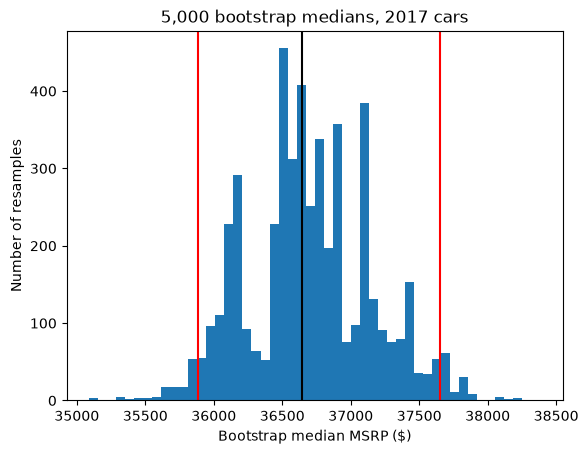

Lincoln n = 46 median: 46060.0 95% interval: $41550.0 to $49025.0


In [ ]:
def bootstrap_median(values, n_boot=5000):
    """Return an array of n_boot bootstrap medians."""
    # hint: rng.choice(values, size=len(values), replace=True)

    valuesArray = np.asarray(values)
    sampleSize = len(valuesArray)  
    bootstrapMedians = np.empty(n_boot)
    
    for i in range(n_boot):
        resample = rng.choice(valuesArray, size=sampleSize, replace=True)
        bootstrapMedians[i] = np.median(resample)  # median of this one fake market
    
    return bootstrapMedians

    pass

# a, b)

prices_2017 = clean.loc[clean["year"] == 2017, "msrp"].dropna()
median_msrp_2017 = prices_2017.median()
print(f"Median: {median_msrp_2017}")

# a) Median: 36647.5

bootMedians = bootstrap_median(prices_2017)
lowerBound, upperBound = np.percentile(bootMedians, [2.5, 97.5])
print(f"95% interval: ${lowerBound:,.0f} to ${upperBound:,.0f}")

plt.hist(bootMedians, bins=50)
plt.axvline(lowerBound, color="red")                  
plt.axvline(upperBound, color="red")
plt.axvline(median_msrp_2017, color="black")          
plt.xlabel("Bootstrap median MSRP ($)")
plt.ylabel("Number of resamples")
plt.title("5,000 bootstrap medians, 2017 cars")
plt.show()


# c) I chose Lincoln make, the interval is wider because we have a much smaller sample size

lincoln_prices_2017 = clean.loc[(clean["year"] == 2017) & (clean["make"] == "Lincoln"), "msrp"]
lincoln_median_2017 = lincoln_prices_2017.median()
lincoln_boot_medians = bootstrap_median(lincoln_prices_2017)

lower_bound_lincoln, upper_bound_lincoln = np.percentile(lincoln_boot_medians, [2.5, 97.5])

print(f"Lincoln n = {len(lincoln_prices_2017)} median: {lincoln_median_2017} 95% interval: ${lower_bound_lincoln} to ${upper_bound_lincoln}")




**Answer: We are 95% confident that the typical price of a 2017 car is between about $41,550 and $49,025.**

---
## Part 4: Testing

### Q5. Can marketing say "our 2017 compacts average over 30 MPG"?

a) Write H₀ and Hₐ. One-sided or two-sided? Why?

b) How many cars are in the sample, and what does the distribution look like? Is a t-test reasonable here?

c) Run a one-sample t-test at α = 0.05 (`stats.ttest_1samp(..., alternative="greater")`). State the conclusion in plain English.

d) **Independence check.** Tests assume each row is an independent observation. Count how many rows each `make` + `model` has in this sample. Then average to one row per model and rerun the test. What changed, and which version do you trust more?

n = 526
mean = 30.75, median = 30.0, std = 6.07, skew = 0.58


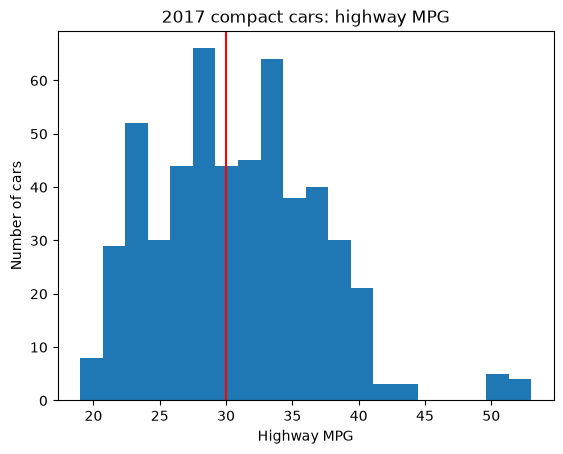

t = 2.84, p = 0.00233
make       model          
Toyota     Tacoma             32
Chevrolet  Corvette           24
Nissan     Frontier           22
           370Z               17
Ford       Transit Connect    16
Porsche    911                14
Honda      Civic              13
Audi       A3                 12
dtype: int64
85 models, median 6 rows each, max 32
n = 85, mean = 31.69, t = 2.58, p = 0.0059


In [54]:
# a) a) H₀: μ = 30. Hₐ: μ > 30. It's one-sided because the claim is "over 30". 

# H₀: the true average highway MPG of 2017 compacts is 30 (μ = 30).
# Hₐ: the true average is greater than 30 (μ > 30).
# One-sided because marketing's claim is specifically "over 30". 
# Only evidence in that direction can support it, and you have to choose the direction before looking at the data.

# b) sample: 2017 compact cars (MPG you trust); n, mean, histogram

compact_cars_2017 = clean[(clean["year"] == 2017)
                        & (clean["vehicle_size"] == "Compact")
                        & (clean["engine_fuel_type"] != "electric")]
compact_cars_2017 = compact_cars_2017.dropna(subset=["highway_mpg"]).copy()
highway_mpg_compact = compact_cars_2017["highway_mpg"]  

print(f"n = {len(highway_mpg_compact)}")
print(f"mean = {highway_mpg_compact.mean():.2f}, median = {highway_mpg_compact.median():.1f}, "
      f"std = {highway_mpg_compact.std():.2f}, skew = {stats.skew(highway_mpg_compact):.2f}")

plt.hist(highway_mpg_compact, bins=20)
plt.axvline(30, color="red")                             
plt.xlabel("Highway MPG")
plt.ylabel("Number of cars")
plt.title("2017 compact cars: highway MPG")
plt.show()

# c) one-sample t-test vs 30
tTestResult = stats.ttest_1samp(highway_mpg_compact, 30, alternative="greater")
print(f"t = {tTestResult.statistic:.2f}, p = {tTestResult.pvalue:.5f}")


# d) rows per make+model, then one row per model and retest

rows_per_model = compact_cars_2017.groupby(["make", "model"]).size().sort_values(ascending=False)
print(rows_per_model.head(8))
print(f"{len(rows_per_model)} models, median {rows_per_model.median():.0f} rows each, max {rows_per_model.max()}")

# Average highway MPG to ONE value per model, then rerun the same test
mpg_per_model = compact_cars_2017.groupby(["make", "model"])["highway_mpg"].mean()
per_model_result = stats.ttest_1samp(mpg_per_model, 30, alternative="greater")
print(f"n = {len(mpg_per_model)}, mean = {mpg_per_model.mean():.2f}, "
      f"t = {per_model_result.statistic:.2f}, p = {per_model_result.pvalue:.4f}")

**Answer:**

### Q6. Do manual cars cost less? (the big one)

A sales rep says: *"Manual cars are way cheaper. We should push manuals to budget shoppers."*

Compare `AUTOMATIC` vs `MANUAL` only.

a) Compare the median MSRP of the two groups.

b) Before believing it, compare the `year` of manual vs automatic cars. What do you notice?

c) Redo (a) using only 2015–2017 cars, then within each `vehicle_size`. For 2015–17 compacts, use the Mann–Whitney U test (`stats.mannwhitneyu(auto, manual)`) to compare prices.

- What do the p-value and medians suggest?

d) Write one sentence back to the sales rep.

In [55]:
# a) compare median MSRP by transmission type
autoVsManual = clean[clean["transmission_type"].isin(["AUTOMATIC", "MANUAL"])]

# groupby splits into two piles, then we summarize msrp in each (median skips NaN automatically)
medianPriceByTransmission = autoVsManual.groupby("transmission_type")["msrp"].median()
print(medianPriceByTransmission)

# b) compare year by transmission type
yearByTransmission = autoVsManual.groupby("transmission_type")["year"].agg(["median", "mean"])
print(yearByTransmission)

# Share of each group that is from the 1990s (True counts as 1, so .mean() is the fraction)
nineties = (autoVsManual["year"] <= 1999)
print(nineties.groupby(autoVsManual["transmission_type"]).mean())

# c) compare 2015-2017 medians overall and within each vehicle_size
# For 2015-17 compacts, test automatic vs manual prices with:
# stats.mannwhitneyu(auto, manual)

recentCars = autoVsManual[autoVsManual["year"].between(2015, 2017)]

print(recentCars.groupby("transmission_type")["msrp"].median())

print(recentCars.pivot_table(index="vehicle_size", columns="transmission_type",
                             values="msrp", aggfunc=["count", "median"]))

compactRecent = recentCars[recentCars["vehicle_size"] == "Compact"]
autoPrices   = compactRecent.loc[compactRecent["transmission_type"] == "AUTOMATIC", "msrp"].dropna()
manualPrices = compactRecent.loc[compactRecent["transmission_type"] == "MANUAL", "msrp"].dropna()
mannWhitneyResult = stats.mannwhitneyu(autoPrices, manualPrices)
print(f"U = {mannWhitneyResult.statistic:.0f}, p = {mannWhitneyResult.pvalue:.3f}")

transmission_type
AUTOMATIC    33360.0
MANUAL       22270.0
Name: msrp, dtype: float64
                   median         mean
transmission_type                     
AUTOMATIC          2015.0  2011.717276
MANUAL             2008.0  2005.760136
transmission_type
AUTOMATIC    0.069078
MANUAL       0.325043
Name: year, dtype: float64
transmission_type
AUTOMATIC    36732.5
MANUAL       27090.0
Name: msrp, dtype: float64
                      count           median         
transmission_type AUTOMATIC MANUAL AUTOMATIC   MANUAL
vehicle_size                                         
Compact                1175    619   25990.0  26255.0
Large                  1489     26   44540.0  38395.0
Midsize                2008    210   37605.0  26920.0
U = 346203, p = 0.094


**Answer: Manuals are about $11,000 cheaper, but that is mostly because they're older and smaller; among comparable 2015–2017 compacts prices are basically the same, so I wouldn't push manuals as the budget option.**

### Q7. Significant ≠ important

Among cars whose MPG you trust, 4-door cars get better highway MPG than 2-door cars.

a) Run a Welch t-test. Report the difference in means and the p-value.

b) Translate the difference into dollars. Assume 12,000 miles/year and \$3.50/gallon. How much does the average 4-door driver save per year?

c) Now pretend you only had **30 cars per group.** Draw 30 random 4-door and 30 random 2-door cars, run the same test, and repeat 1,000 times. What fraction of those tests come out significant (p < 0.05)?

d) Would you put "4-door cars are significantly more fuel-efficient" in an ad? What would you say instead?

In [56]:
# a) Welch t-test, 4-door vs 2-door
trustedCars = clean[(clean["engine_fuel_type"] != "electric")
                    & (clean["number_of_doors"].isin([2, 4]))]
trustedCars = trustedCars.dropna(subset=["highway_mpg"])

fourDoorMpg = trustedCars.loc[trustedCars["number_of_doors"] == 4, "highway_mpg"]
twoDoorMpg  = trustedCars.loc[trustedCars["number_of_doors"] == 2, "highway_mpg"]

welchResult = stats.ttest_ind(fourDoorMpg, twoDoorMpg, equal_var=False)
mpgDifference = fourDoorMpg.mean() - twoDoorMpg.mean()
print(f"4-door: {fourDoorMpg.mean():.2f} (n={len(fourDoorMpg)}), 2-door: {twoDoorMpg.mean():.2f} (n={len(twoDoorMpg)})")
print(f"difference = {mpgDifference:.2f} MPG, t = {welchResult.statistic:.2f}, p = {welchResult.pvalue:.2e}")

# b) yearly gas cost = miles * price_per_gallon / mpg
milesPerYear = 12000
pricePerGallon = 3.50

yearlyGasCostFourDoor = milesPerYear * pricePerGallon / fourDoorMpg.mean()
yearlyGasCostTwoDoor  = milesPerYear * pricePerGallon / twoDoorMpg.mean()
yearlySavings = yearlyGasCostTwoDoor - yearlyGasCostFourDoor
print(f"4-door ${yearlyGasCostFourDoor:,.0f}, 2-door ${yearlyGasCostTwoDoor:,.0f}, saving ${yearlySavings:,.0f} per year")

# c) simulation
fourDoorArray = fourDoorMpg.to_numpy()
twoDoorArray = twoDoorMpg.to_numpy()

n_sims, hits = 1000, 0
for _ in range(n_sims):
    smallSampleFour = rng.choice(fourDoorArray, 30, replace=False)
    smallSampleTwo  = rng.choice(twoDoorArray, 30, replace=False)
    smallTestResult = stats.ttest_ind(smallSampleFour, smallSampleTwo, equal_var=False)
    if smallTestResult.pvalue < 0.05:
        hits += 1
    pass

print(f"{hits} of {n_sims} small studies were significant ({hits / n_sims:.1%})")

4-door: 26.93 (n=8295), 2-door: 25.28 (n=3157)
difference = 1.65 MPG, t = 12.51, p = 1.62e-35
4-door $1,560, 2-door $1,661, saving $102 per year
156 of 1000 small studies were significant (15.6%)


**Answer: I would not say "significantly more fuel-efficient" in an ad, since customers would read it as a large difference when it is worth about $100 a year, and door count is tied to body style and model year, so it is not clear that doors cause the gain. I'd say: "4-door cars in our listings average about 1.5 more highway MPG, roughly $100 a year in gas.**

---
## Part 5: Communicate

### Q8. Your memo to the pricing manager

Write 4–6 sentences. Include:
- Your answer to "do manual cars cost less?", with at least one number
- One other finding from this notebook that matters for pricing
- One limitation of this data a manager should know about

No unexplained jargon: if you say "significant," say what it means.

**Memo:  Manual cars look cheaper, with a median sticker price of about $21,800 versus $33,600 for automatics, but that gap is mostly misleading. Manuals in our data are older (median model year 2008 versus 2015) and mostly small cars (72% of 2015–2017 manuals are compacts versus 25% of automatics), and older, smaller cars simply have lower prices. When comparing only 2015–2017 compacts, the median prices are nearly identical ($25,860 for manual versus $25,995 for automatic). A statistical test agrees: a gap that small would show up by luck alone about 1 time in 5, so there's no clear price difference and I would not pitch manuals to budget shoppers as the cheaper choice. Separately, when we quote a "typical" price we should use the median (about $31,800) rather than the average ($44,800), because a handful of exotic cars (six priced over $1 million) pull the average up. One limitation is that about 750 listings of 1990–2000 cars carried an identical placeholder price of $2,000, which I removed as unreliable, and manuals were hit harder (17% of manuals had no usable price versus 4% of automatics), so our picture of older manual prices is thin.**

---
## 🚀 Stretch (optional)

### 🚀 S1. Horsepower and price

a) Compute the correlation between `engine_hp` and `msrp` three ways: Pearson, Pearson with `np.log10(msrp)`, and Spearman. Why do they differ?

b) Scatter plot HP vs MSRP with a log y-axis (`plt.yscale("log")`).

c) Does adding horsepower *cause* a higher price? Name one lurking variable.

In [ ]:
# S1

### 🚀 S2. Is transmission tied to vehicle size?

For 2015–2017 cars (automatic and manual only), build a crosstab of `vehicle_size` × `transmission_type` and run a chi-square test (`stats.chi2_contingency`). How does this connect to Q6?

In [ ]:
# S2